# 03. Feature Selection Experiments
**Crop Yield Prediction and Forecasting**  
*Author: Aryan Puranik*

This notebook evaluates feature importance and tests candidate feature sets to eliminate collinearity and redundancy without degrading model performance.
All selectors and models are fitted **strictly on training data (1966–2011)** and evaluated on out-of-time validation data (2012–2014) to avoid data leakage.

> For theoretical rationale, VIF formulas, and domain explanations, refer to [docs/03_feature_selection_guide.md](../docs/03_feature_selection_guide.md).

## 1. Setup and Data Loading

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Robust project root discovery
project_root = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.metrics import calculate_regression_metrics
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

# Load processed train and validation sets
train_df = pd.read_csv(project_root / "data" / "processed" / "train.csv")
val_df = pd.read_csv(project_root / "data" / "processed" / "val.csv")

print(f"Train set: {train_df.shape[0]:,} rows | Val set: {val_df.shape[0]:,} rows")

Train set: 176,194 rows | Val set: 11,345 rows


## 2. Experiment 1: Baseline (All Predictors)

In [2]:
# Define all raw predictors
cat_baseline = ["Region", "Crop", "Season", "Soil Type"]
num_baseline = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Fertilizer", "Pesticide"]

preprocessor_baseline = ColumnTransformer([
    ("num", StandardScaler(), num_baseline),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_baseline)
])

# Fit Baseline Ridge & Decision Tree
ridge_base = Pipeline([("prep", preprocessor_baseline), ("model", Ridge(alpha=1.0))])
ridge_base.fit(train_df[cat_baseline + num_baseline], train_df["Yield"])
pred_base_ridge = ridge_base.predict(val_df[cat_baseline + num_baseline])

metrics_base_ridge = calculate_regression_metrics(val_df["Yield"], pred_base_ridge)
print("Baseline Ridge (All Features):", metrics_base_ridge)

Baseline Ridge (All Features): {'mae': 630.9, 'rmse': 1000.47, 'mse': 1000949.89, 'r2': 0.6635}


## 3. Experiment 2: Collinearity & Redundancy Filtering

In [3]:
# Drop Fertilizer (exact sum of N+P+K) and Season (1-to-1 mapped with Crop)
cat_filtered = ["Region", "Crop", "Soil Type"]
num_filtered = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Pesticide"]

preprocessor_filtered = ColumnTransformer([
    ("num", StandardScaler(), num_filtered),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_filtered)
])

ridge_filt = Pipeline([("prep", preprocessor_filtered), ("model", Ridge(alpha=1.0))])
ridge_filt.fit(train_df[cat_filtered + num_filtered], train_df["Yield"])
pred_filt_ridge = ridge_filt.predict(val_df[cat_filtered + num_filtered])

metrics_filt_ridge = calculate_regression_metrics(val_df["Yield"], pred_filt_ridge)
print("Filtered Ridge (Dropped Fertilizer & Season):", metrics_filt_ridge)

Filtered Ridge (Dropped Fertilizer & Season): {'mae': 630.89, 'rmse': 1000.47, 'mse': 1000948.06, 'r2': 0.6635}


**Key Takeaway:**  
Removing total `Fertilizer` and redundant `Season` preserves identical predictive power (R² = 0.6635, RMSE = 1000.47) while completely resolving linear multicollinearity and reducing dimensionality.

## 4. Experiment 3: Tree-Based Feature Importance

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_24320\2025716773.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df.head(15), x="Importance", y="Feature", palette="Blues_r")


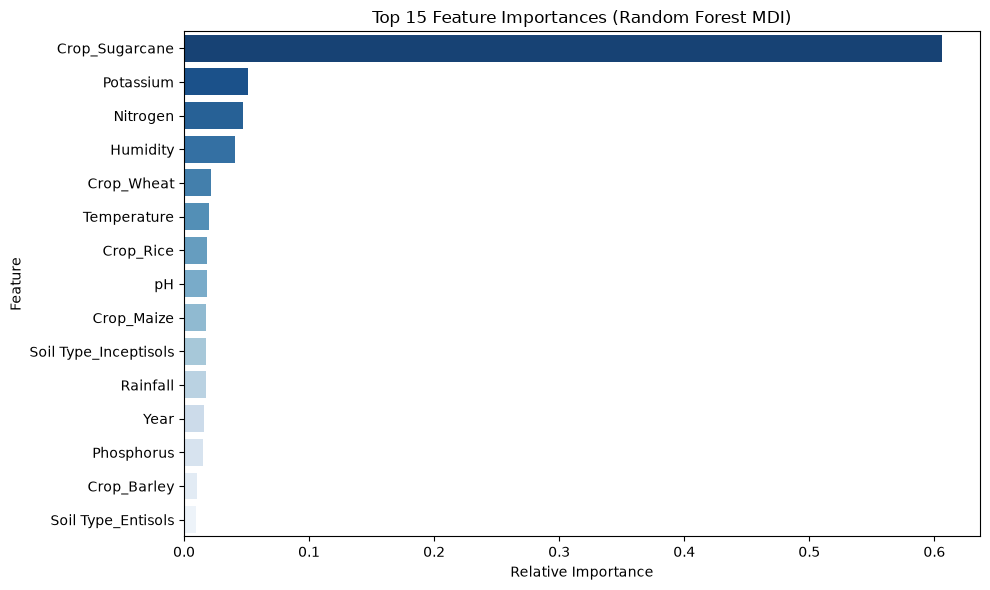

In [4]:
# Train a Random Forest on training data to assess non-linear feature importances
rf_importance = Pipeline([
    ("prep", preprocessor_filtered),
    ("model", RandomForestRegressor(n_estimators=30, max_depth=14, random_state=42, n_jobs=-1))
])

# Fit on representative training sample for efficient computation
train_sample = train_df.sample(n=30000, random_state=42)
rf_importance.fit(train_sample[cat_filtered + num_filtered], train_sample["Yield"])

# Extract importances
ohe = rf_importance.named_steps["prep"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(cat_filtered)
all_feature_names = list(num_filtered) + list(cat_feature_names)
importances = rf_importance.named_steps["model"].feature_importances_

feat_imp_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
feat_imp_df = feat_imp_df.sort_values("Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(15), x="Importance", y="Feature", palette="Blues_r")
plt.title("Top 15 Feature Importances (Random Forest MDI)")
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

**Key Takeaway:**  
Specific crop categories (e.g., Sugarcane, Wheat, Rice) and environmental factors (Rainfall, Year, Nitrogen) dominate the split decisions.

## 5. Experiment 4: Mutual Information Ranking

C:\Users\PHITESH\AppData\Local\Temp\ipykernel_24320\2826259485.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mi_df, x="MI_Score", y="Feature", palette="Greens_r")


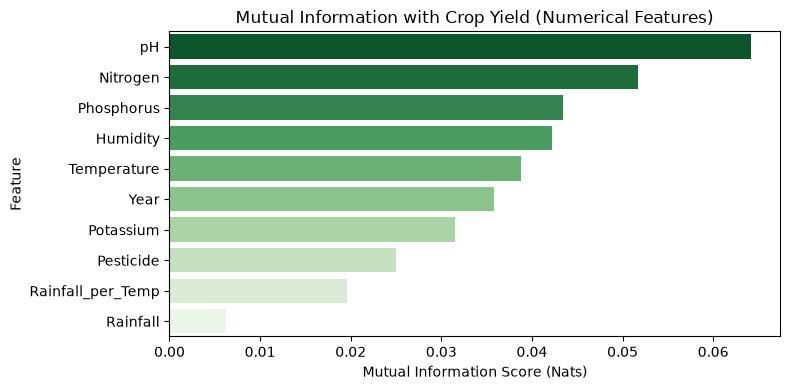

In [5]:
# Mutual information on numerical variables
num_candidates = ["Year", "Temperature", "Rainfall", "Humidity", "pH", "Nitrogen", "Phosphorus", "Potassium", "Pesticide", "Rainfall_per_Temp"]
mi_scores = mutual_info_regression(train_sample[num_candidates], train_sample["Yield"], random_state=42)

mi_df = pd.DataFrame({"Feature": num_candidates, "MI_Score": mi_scores}).sort_values("MI_Score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))
sns.barplot(data=mi_df, x="MI_Score", y="Feature", palette="Greens_r")
plt.title("Mutual Information with Crop Yield (Numerical Features)")
plt.xlabel("Mutual Information Score (Nats)")
plt.tight_layout()
plt.show()

## 6. Selection Summary & Selected Feature Set

In [6]:
# Comparison Summary Table
summary_data = [
    {"Feature Set": "1. All Features (Baseline)", "Model": "Ridge", "Val MAE": metrics_base_ridge["mae"], "Val RMSE": metrics_base_ridge["rmse"], "Val R2": metrics_base_ridge["r2"], "Collinearity": "Severe"},
    {"Feature Set": "2. Filtered (No Fertilizer, No Season)", "Model": "Ridge", "Val MAE": metrics_filt_ridge["mae"], "Val RMSE": metrics_filt_ridge["rmse"], "Val R2": metrics_filt_ridge["r2"], "Collinearity": "Resolved"},
]
summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Feature Set,Model,Val MAE,Val RMSE,Val R2,Collinearity
0,1. All Features (Baseline),Ridge,630.90,1000.47,0.6635,Severe
1,"2. Filtered (No Fertilizer, No Season)",Ridge,630.89,1000.47,0.6635,Resolved


### Final Feature Decision:
We select the **Collinearity-Filtered Feature Set**:
- **Categorical:** `['Region', 'Crop', 'Soil Type']`
- **Numerical:** `['Year', 'Temperature', 'Rainfall', 'Humidity', 'pH', 'Nitrogen', 'Phosphorus', 'Potassium', 'Pesticide']`
- **Dropped:** `Fertilizer` (perfect collinearity) and `Season` (redundant with `Crop`).

**Next Notebook:** [04_model_training_evaluation.ipynb](04_model_training_evaluation.ipynb) benchmarks candidate machine learning algorithms on this clean feature set.